[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/08_HMM_Viterbi_and_Final_Comparison.ipynb)

# 08. HMM / Viterbi route reconstruction and final comparison of all models
**Run on:** Laptop B · **Approx. runtime:** ~5-8 min on a 4-core laptop

Uses the **saved model files** in `models/`, so it runs independently of the other notebooks.

**HMM design (`pathsnap/hmm.py`):**
- **Hidden states:** the candidate arcs of each GPS point.
- **Emission:** `w · log P(classifier says this candidate is the reference arc)`.
- **Transition:** `−|d_route − d_gc| / β`, where `d_route` is the network distance between the two projections (Dijkstra on the directed road graph, with a cut-off) and `d_gc` is the straight-line distance between the GPS points.
- **Edge cases:**
  - unreachable pairs get a floor log-probability, so the chain never breaks
  - gaps over 30 s use uniform transitions (the chain restarts)
  - points without candidates are skipped
- **Viterbi:**
  - **forward pass:** for each point and candidate, keep the best score of any path ending there, `δ_t(j) = max_i [δ_{t−1}(i) + log A(i→j)] + log B_t(j)`, plus a back-pointer
  - **backward pass:** follow the back-pointers from the best final state
- Consecutive decoded arcs that aren't adjacent are joined with shortest paths to form the route.
- Decoder parameters (`models/hmm_params.json`) were tuned with Optuna on **training trips only** (`scripts/04_hmm_eval.py`).

**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [ ]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [1]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap


In [2]:
tr, tr_pts, te, te_pts = nb.load_data()

feature tables found in artifacts/


train: 78 trips, 1,028,261 candidate rows, positive rate 0.175
student_test: 10 trips, 113,636 candidate rows


## 1. All saved models on the student-test trips

In [3]:
import joblib, json
from pathsnap.experiment import evaluate
names = {"logreg": "Logistic Regression", "gnb": "Gaussian NB", "knn": "KNN", "dtree": "Decision Tree",
         "rf": "Random Forest", "extratrees": "Extra Trees", "histgb": "HistGB", "lightgbm": "LightGBM",
         "mlp": "MLP", "final": "LightGBM tuned (deployed)"}
models, rows = {}, []
for k, n in names.items():
    models[k] = joblib.load(f"models/{k}.joblib")
    m, _ = evaluate(models[k], te, te_pts)
    rows.append({"model": n, "test Top-1": m["top1"], "test macro F1": m["macro_f1"], "precision": m["precision"],
                 "recall": m["recall"], "log loss": m["log_loss"], "ms/point": m["infer_ms_per_point"]})
    print("evaluated", n)
cmp = pd.DataFrame(rows).set_index("model")
near = te[te.dist_rank == 0][["trip", "point", "arc"]]
mm = te_pts[te_pts.true_arc >= 0].merge(near, on=["trip", "point"], how="left")
print(f"nearest-arc baseline Top-1: {(mm.arc == mm.true_arc).mean():.4f}")
cmp.sort_values("test Top-1", ascending=False).round(4)

evaluated Logistic Regression


evaluated Gaussian NB


evaluated KNN
evaluated Decision Tree


evaluated Random Forest


evaluated Extra Trees


evaluated HistGB


evaluated LightGBM
evaluated MLP


evaluated LightGBM tuned (deployed)
nearest-arc baseline Top-1: 0.5418


,test Top-1,test macro F1,precision,recall,log loss,ms/point
model,,,,,,
LightGBM,0.8871,0.9283,0.8925,0.8684,0.1039,0.0359
LightGBM tuned (deployed),0.8859,0.9282,0.8899,0.8709,0.1040,0.0418
MLP,0.8807,0.9216,0.8909,0.8478,0.1134,0.0026
HistGB,0.8796,0.9241,0.8769,0.8701,0.1079,0.0065
Random Forest,0.8777,0.9224,0.9002,0.8417,0.1105,0.0220
Decision Tree,0.8756,0.9224,0.8753,0.8662,0.1293,0.0006
Logistic Regression,0.8621,0.9034,0.8372,0.8416,0.1510,0.0011
KNN,0.8577,0.9124,0.8676,0.8404,0.1811,3.2343
Extra Trees,0.8552,0.9158,0.9022,0.8190,0.1400,0.0205


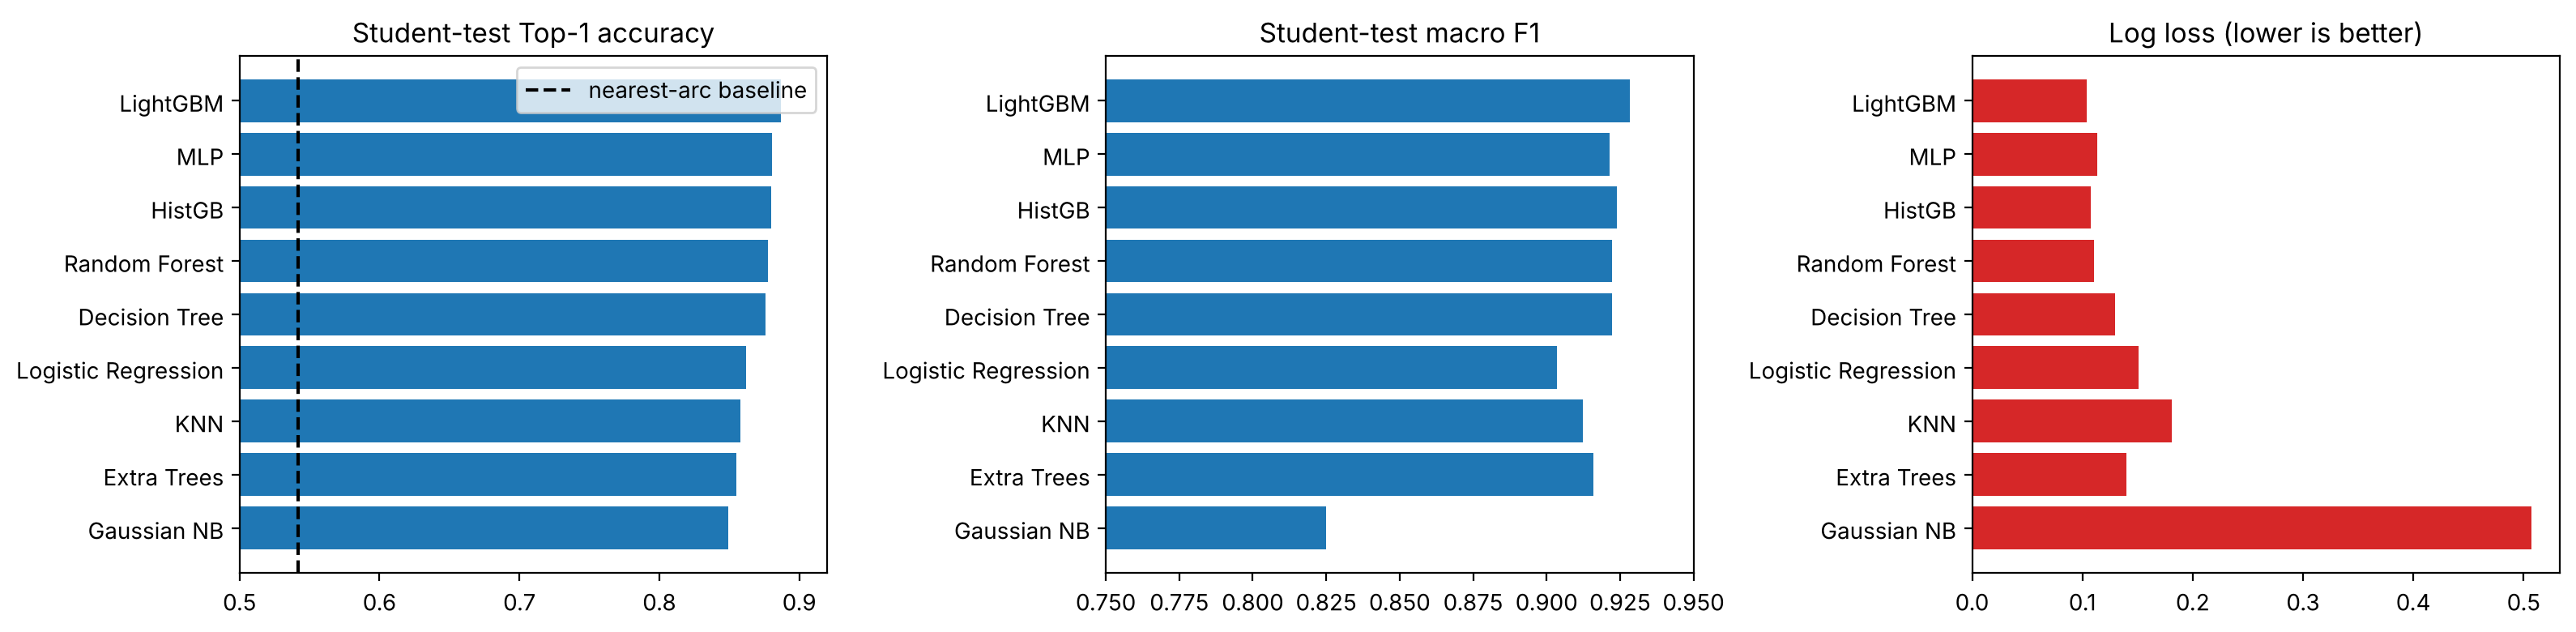

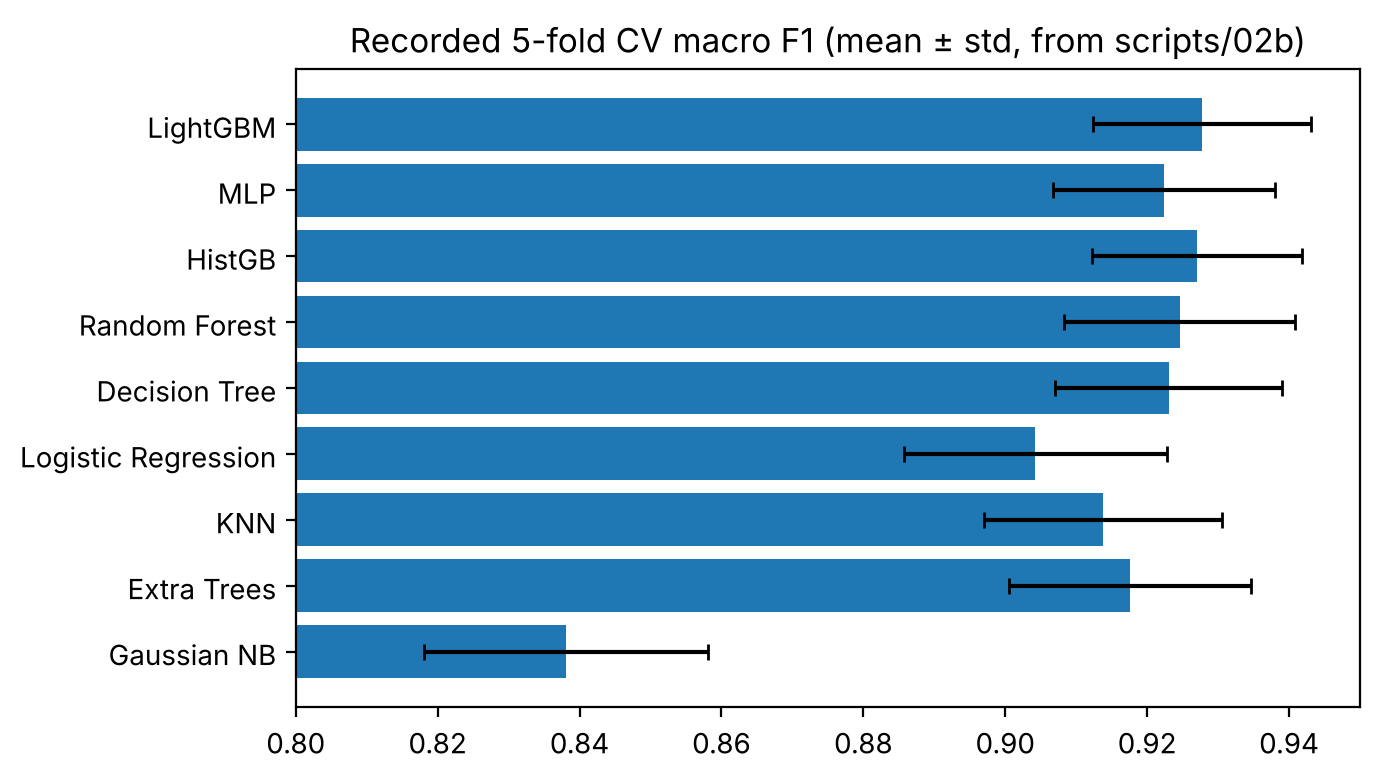

In [4]:
cv_rec = pd.read_csv("results/03_concurrent_training/model_comparison.csv").set_index("model")   # recorded 5-fold CV (scripts/02b)
c = cmp.drop(index="LightGBM tuned (deployed)").sort_values("test Top-1")
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].barh(c.index, c["test Top-1"]); ax[0].set(title="Student-test Top-1 accuracy", xlim=(0.5, 0.92))
ax[0].axvline((mm.arc == mm.true_arc).mean(), color="k", ls="--", label="nearest-arc baseline"); ax[0].legend()
ax[1].barh(c.index, c["test macro F1"]); ax[1].set(title="Student-test macro F1", xlim=(0.75, 0.95))
ax[2].barh(c.index, c["log loss"], color="#d62728"); ax[2].set(title="Log loss (lower is better)")
fig.tight_layout(); nb.show()
key = {v: k for k, v in names.items()}
cvf = pd.Series({n: cv_rec.loc[key[n], "cv_macro_f1"] for n in c.index}); cvs = pd.Series({n: cv_rec.loc[key[n], "cv_macro_f1_std"] for n in c.index})
plt.figure(figsize=(7, 4)); plt.barh(cvf.index, cvf, xerr=cvs, capsize=3); plt.xlim(0.8, 0.95)
plt.title("Recorded 5-fold CV macro F1 (mean ± std, from scripts/02b)"); plt.tight_layout(); nb.show()

## 2. Classifier only vs classifier + HMM for the top-3 classifiers
The same decoder parameters are used for all three; only the emission probabilities change.

In [5]:
top3 = {"LightGBM tuned (deployed)": "final", "MLP": "mlp", "HistGB": "histgb"}
hmm_runs = {n: nb.hmm_compare(models[k], te, n) for n, k in top3.items()}
cols = ["cls_top1", "hmm_top1", "cls_route_precision", "hmm_route_precision", "cls_route_f1", "hmm_route_f1",
        "cls_continuity", "hmm_continuity"]
top3_table = pd.DataFrame({n: d[cols].mean() for n, d in hmm_runs.items()}).T.round(4)
top3_table

LightGBM tuned (deployed): mean over 10 trips
cls_top1          0.9017
hmm_top1          0.9491
cls_route_f1      0.7865
hmm_route_f1      0.9583
cls_continuity    0.9329
hmm_continuity    0.9776


MLP: mean over 10 trips
cls_top1          0.8936
hmm_top1          0.9296
cls_route_f1      0.7859
hmm_route_f1      0.9563
cls_continuity    0.9310
hmm_continuity    0.9766


HistGB: mean over 10 trips
cls_top1          0.8964
hmm_top1          0.9492
cls_route_f1      0.7766
hmm_route_f1      0.9579
cls_continuity    0.9285
hmm_continuity    0.9781


,cls_top1,hmm_top1,cls_route_precision,hmm_route_precision,cls_route_f1,hmm_route_f1,cls_continuity,hmm_continuity
LightGBM tuned (deployed),0.9017,0.9491,0.6630,0.9294,0.7865,0.9583,0.9329,0.9776
MLP,0.8936,0.9296,0.6628,0.9257,0.7859,0.9563,0.9310,0.9766
HistGB,0.8964,0.9492,0.6506,0.9286,0.7766,0.9579,0.9285,0.9781


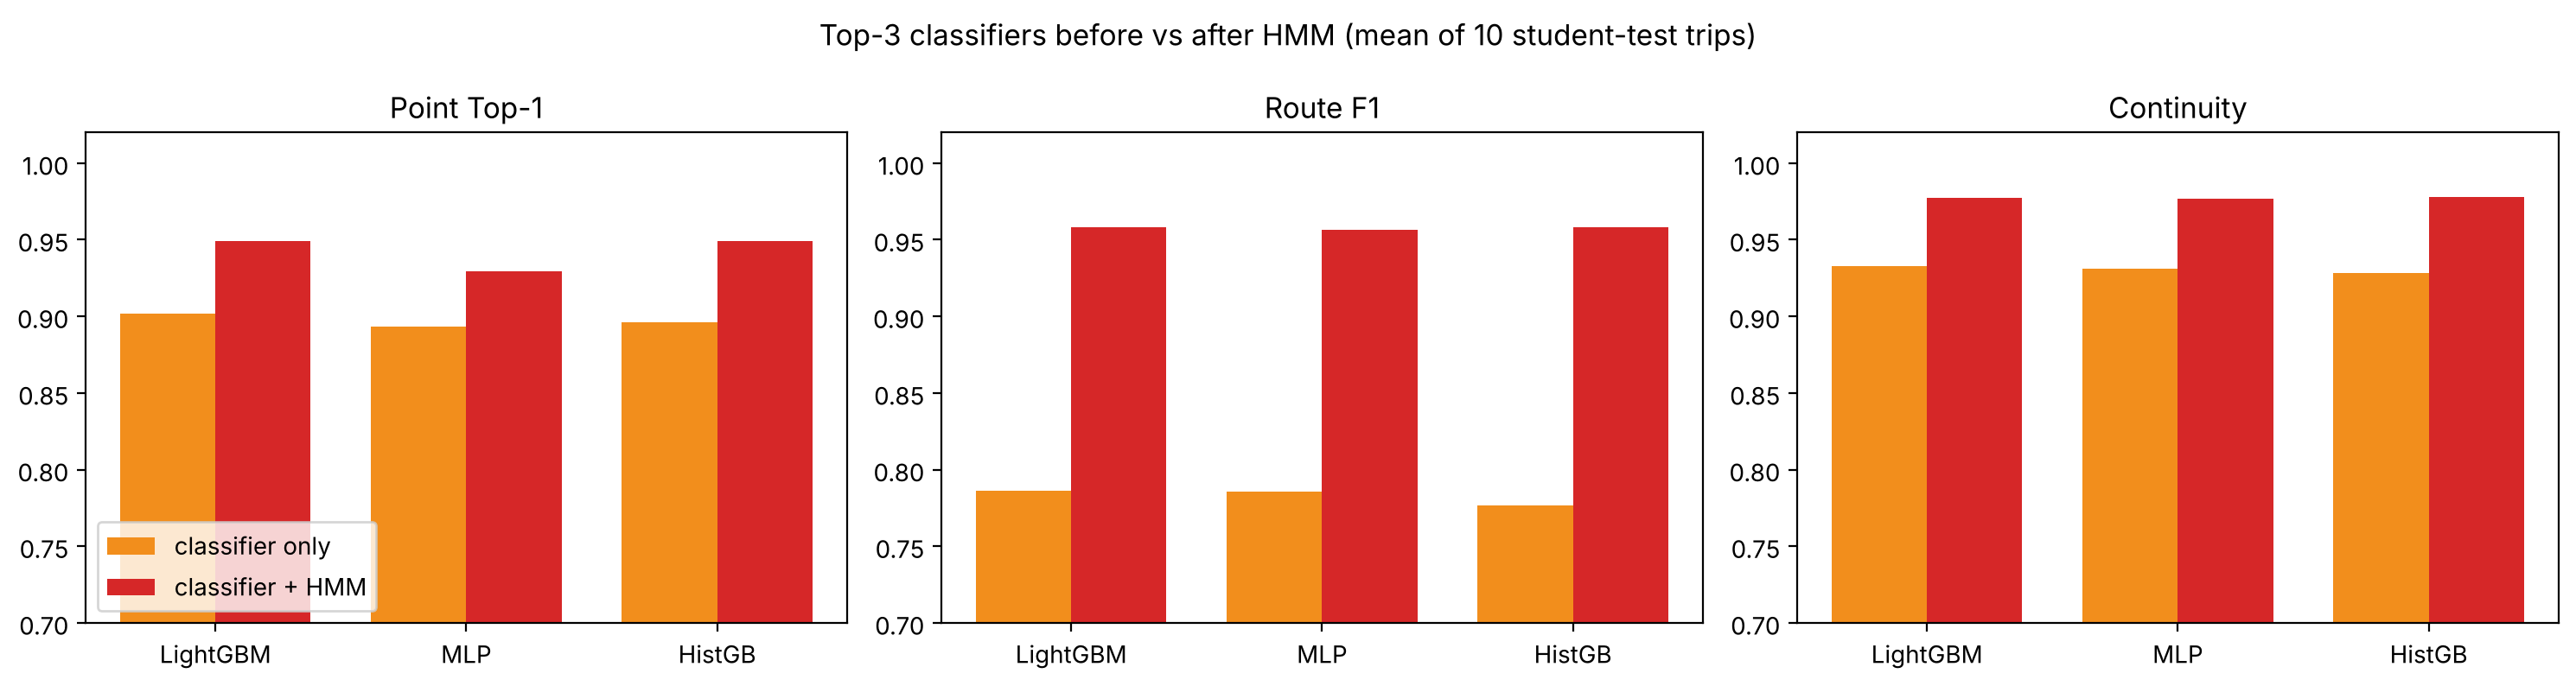

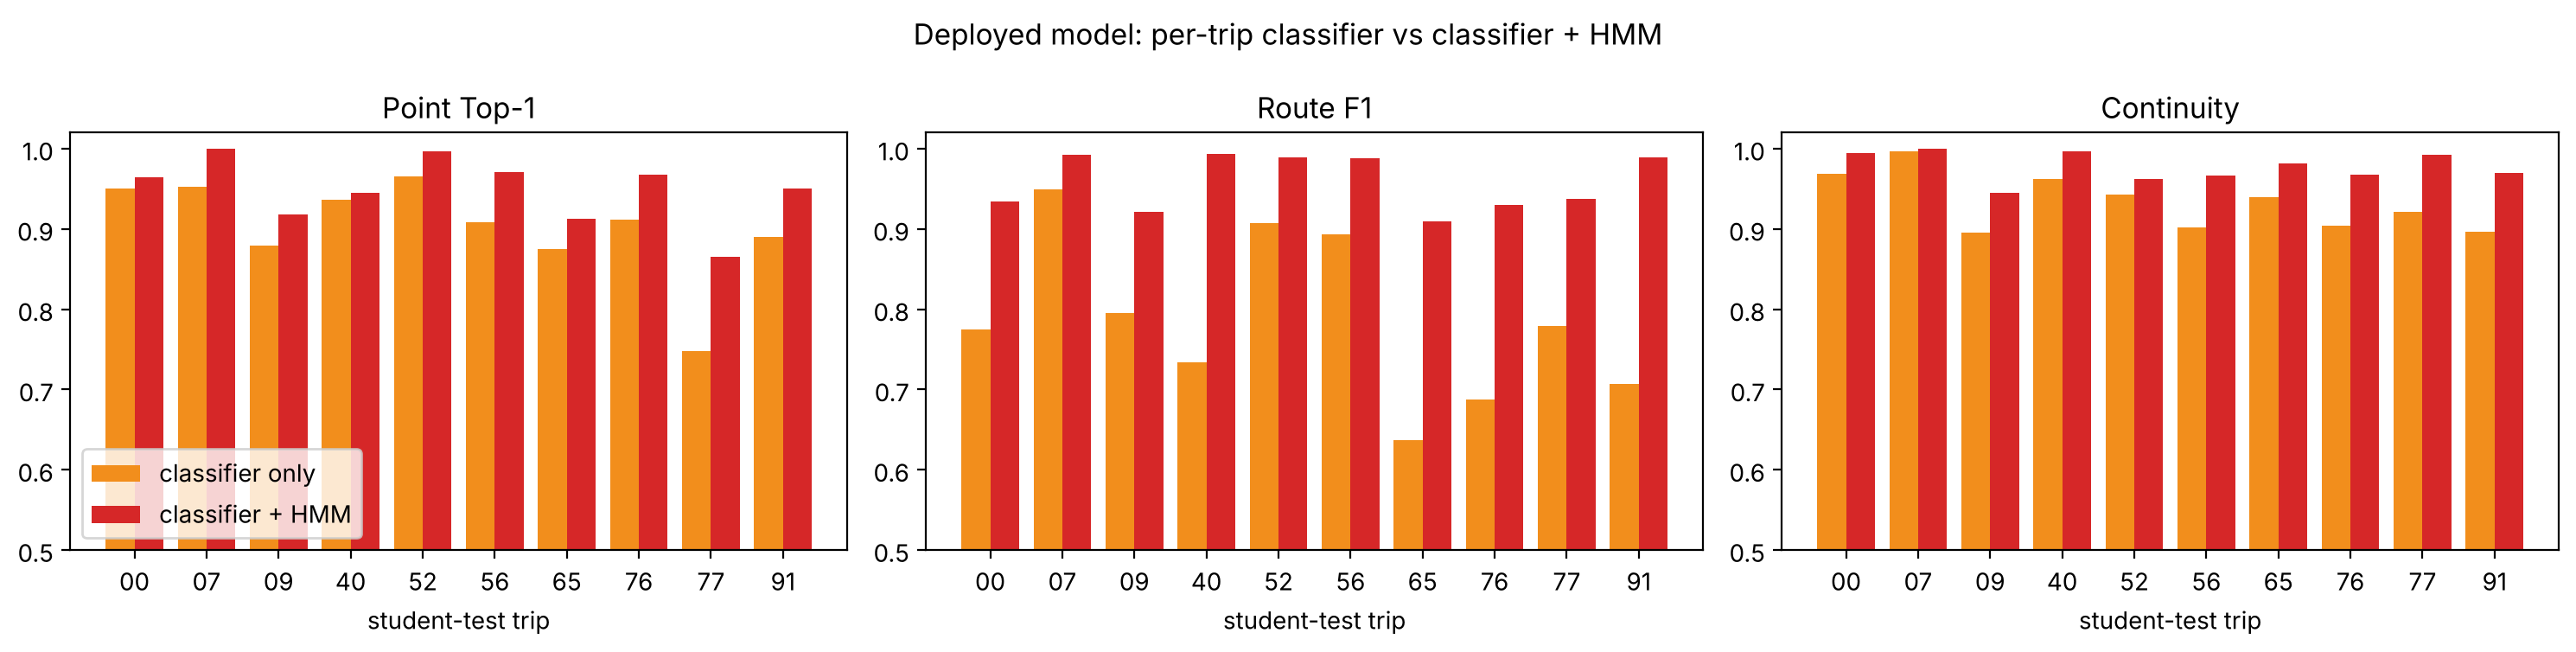

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4)); x = np.arange(3); w = .38
for a, (m, t) in zip(ax, [("top1", "Point Top-1"), ("route_f1", "Route F1"), ("continuity", "Continuity")]):
    a.bar(x - w/2, top3_table[f"cls_{m}"], w, label="classifier only", color="#f28e1c")
    a.bar(x + w/2, top3_table[f"hmm_{m}"], w, label="classifier + HMM", color="#d62728")
    a.set_xticks(x, ["LightGBM", "MLP", "HistGB"]); a.set(title=t, ylim=(0.7, 1.02))
ax[0].legend(loc="lower left"); fig.suptitle("Top-3 classifiers before vs after HMM (mean of 10 student-test trips)")
fig.tight_layout(); nb.show()
nb.plot_hmm(hmm_runs["LightGBM tuned (deployed)"], "Deployed model: per-trip classifier vs classifier + HMM")

## 3. Map: reference vs classifier-only vs HMM route (student_test 00000077, the hardest trip)

In [7]:
from pathsnap.data import load_trip
from pathsnap.pipeline import predict_trip, score_trip
from pathsnap.labels import align_track_to_route
from pathsnap.viz import trip_map
hp = json.load(open("models/hmm_params.json"))
trip = load_trip("data/student_test", "00000077")
out = predict_trip(trip, models["final"], hp)
s = score_trip(trip, out, align_track_to_route(trip, CFG["label_max_dist"])[0])
print({k: round(v, 4) for k, v in s.items() if isinstance(v, float)})
trip_map(trip, [("Reference route", trip.route, "#1a9e3a", 7, None),
                ("Classifier-only route", out["cls_route"], "#f28e1c", 3, "6 6"),
                ("Classifier + HMM route", out["route"], "#d62728", 3, None)],
         f"00000077 | Top-1 cls {s['cls_top1']:.3f} → HMM {s['hmm_top1']:.3f}")

{'cls_top1': 0.7481, 'cls_continuity': 0.921, 'cls_route_precision': 0.6381, 'cls_route_recall': 1.0, 'cls_route_f1': 0.7791, 'hmm_top1': 0.8653, 'hmm_continuity': 0.9928, 'hmm_route_precision': 0.8816, 'hmm_route_recall': 1.0, 'hmm_route_f1': 0.9371}
